# 03 · KPIs, customer segments and win-back

**Questions:** how are revenue, orders, AOV and units moving month on month, and which categories and styles drive them? Who are the high-value, at-risk and churned customers, and what win-back action fits each segment?

**Definitions** (code in `src/fdda/analysis/kpis.py`, `features/rfm.py`, `analysis/cohorts.py`, `analysis/customers.py`):
* *Order* = one customer's purchases on one day in one channel (H&M has no order id).
* *Revenue* = indexed revenue (normalised price × fixed factor).
* *Sold at a discount* = at least 5% below the article-week reference price (see the discount analysis).
* *RFM*: recency = days since last purchase at the snapshot, frequency = distinct purchase days, monetary = indexed revenue; each scored 1–5 by percentile rank. Segments come from an R × F rule table in `config/settings.yaml`.
* *Churned* = no purchase in the last 120 days (90 and 180 shown as sensitivity).

This notebook reads the tables written by `python -m fdda.analysis.customers`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fdda import viz
from fdda.analysis import cohorts
from fdda.config import data_mode, load_settings, resolve_path

settings = load_settings()
MODE = data_mode(settings)
C = resolve_path(settings, "reports") / "customers"
FIGURES = resolve_path(settings, "figures")
W = settings["customers"]["churn_window_days"]
SCOPE = "all customers" if MODE == "full" else "10% customer sample"


def load(name):
    return pd.read_csv(C / f"{name}_{MODE}.csv")


monthly, cat, top_a, top_s = (
    load("monthly_kpis"),
    load("category_share_monthly"),
    load("top_articles"),
    load("top_styles"),
)
seg, sens, prefs, prof = (
    load("segment_summary"),
    load("churn_sensitivity"),
    load("segment_categories"),
    load("segment_discount_profile"),
)
ret, curve, playbook = load("cohort_retention"), load("retention_curve"), load("winback_playbook")
info = json.loads((C / f"customers_summary_{MODE}.json").read_text())
viz.apply_style()
pd.options.display.float_format = "{:,.3f}".format
print(f"Data mode: {MODE} ({SCOPE}); snapshot {info['snapshot_date']}")
pd.Series(info["totals"]).to_frame("value")

Data mode: full (all customers); snapshot 2020-09-23


,value
indexed_revenue,"884,645,974.057"
orders,"9,174,457.000"
units,"31,788,324.000"
customers,"1,362,281.000"
aov,96.425
units_per_order,3.465
discounted_revenue_share,0.323


## 1. Monthly KPIs

Partial months (the first and last month of data) are excluded from the charts and from month-on-month comparisons.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


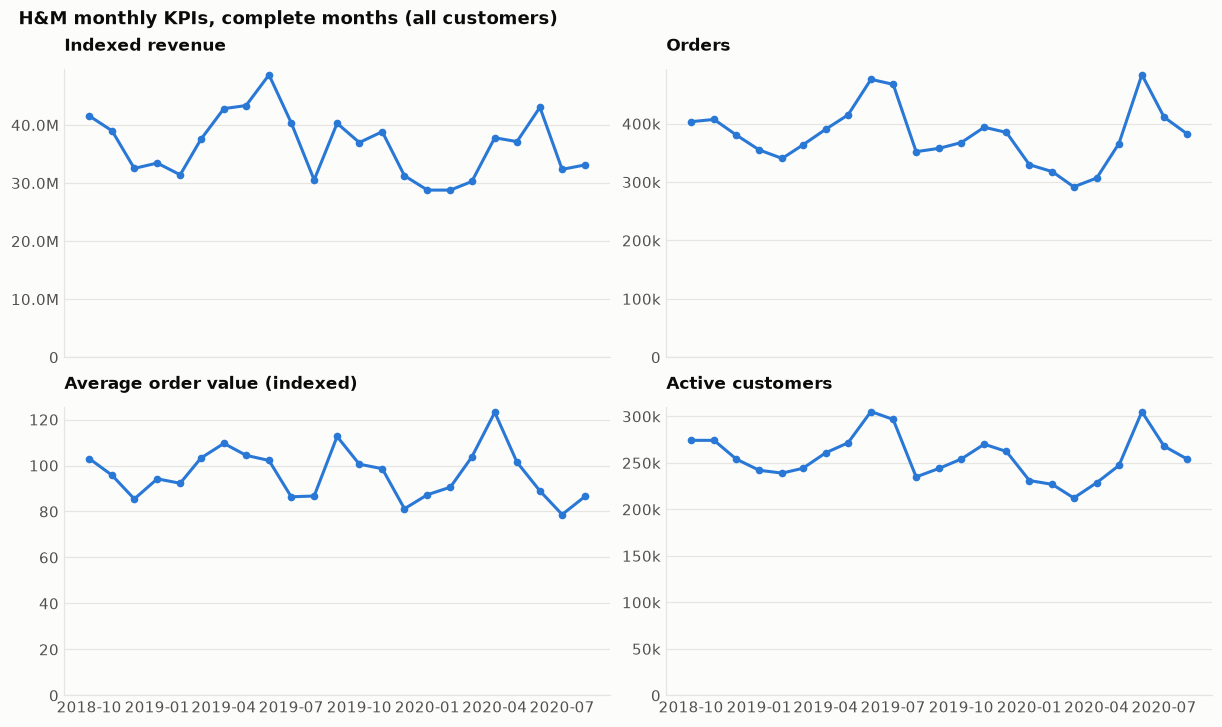

,month,revenue,orders,units,aov,customers,revenue_mom,orders_mom,aov_mom,customers_mom,discounted_revenue_share,is_partial_month
0,2018-09,"17,755,639.593",167434,594776,106.046,140340,NaN,NaN,NaN,NaN,0.232,True
1,2018-10,"41,584,816.610",403548,1397040,103.048,274220,1.342,1.410,-0.028,0.954,0.331,False
2,2018-11,"39,000,988.390",407372,1270619,95.738,274207,-0.062,0.009,-0.071,-0.000,0.421,False
3,2018-12,"32,532,514.712",380742,1148827,85.445,254059,-0.166,-0.065,-0.108,-0.073,0.337,False
4,2019-01,"33,449,981.475",355150,1263471,94.186,242024,0.028,-0.067,0.102,-0.047,0.363,False
5,2019-02,"31,428,221.814",340556,1152412,92.285,238992,-0.060,-0.041,-0.020,-0.013,0.355,False
6,2019-03,"37,549,020.169",363722,1286750,103.235,244166,0.195,0.068,0.119,0.022,0.215,False
7,2019-04,"42,824,987.305",390699,1476454,109.611,260875,0.141,0.074,0.062,0.068,0.204,False
8,2019-05,"43,357,502.322",415180,1560319,104.431,271554,0.012,0.063,-0.047,0.041,0.213,False
9,2019-06,"48,648,417.864",476057,1906202,102.190,305190,0.122,0.147,-0.021,0.124,0.277,False


In [2]:
full = monthly[~monthly.is_partial_month].copy()
full["month_dt"] = pd.to_datetime(full["month"])
panels = [
    ("revenue", "Indexed revenue"),
    ("orders", "Orders"),
    ("aov", "Average order value (indexed)"),
    ("customers", "Active customers"),
]
viz.apply_style()
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained", sharex=True)
for ax, (col, title) in zip(axes.flat, panels, strict=True):
    ax.plot(full["month_dt"], full[col], color=viz.SERIES[0], marker="o", markersize=4)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(bottom=0)
    if col != "aov":
        viz.thousands_axis(ax, "y")
    ax.grid(axis="x", visible=False)
fig.suptitle(
    f"H&M monthly KPIs, complete months ({SCOPE})", x=0.01, ha="left", fontweight="semibold"
)
viz.save_fig(fig, f"kpi_monthly_{MODE}", FIGURES)
plt.show()

cols = [
    "month",
    "revenue",
    "orders",
    "units",
    "aov",
    "customers",
    "revenue_mom",
    "orders_mom",
    "aov_mom",
    "customers_mom",
    "discounted_revenue_share",
    "is_partial_month",
]
display(monthly[cols])

Share of revenue sold at a discount (≥ 5% below the reference price), by month.

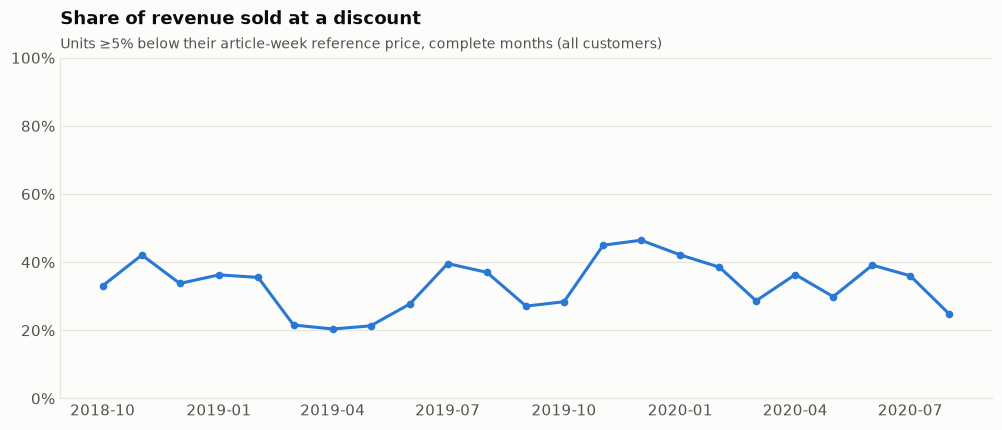

In [3]:
fig, ax = viz.new_fig(9, 3.8)
ax.plot(
    full["month_dt"],
    full["discounted_revenue_share"],
    color=viz.SERIES[0],
    marker="o",
    markersize=4,
)
viz.pct_axis(ax, "y")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Share of revenue sold at a discount", pad=22)
viz.subtitle(ax, f"Units ≥5% below their article-week reference price, complete months ({SCOPE})")
viz.save_fig(fig, f"kpi_discounted_share_{MODE}", FIGURES)
plt.show()

## 2. What drives revenue

Revenue share by product group per month (top 5 groups; the rest folded into *Other*).

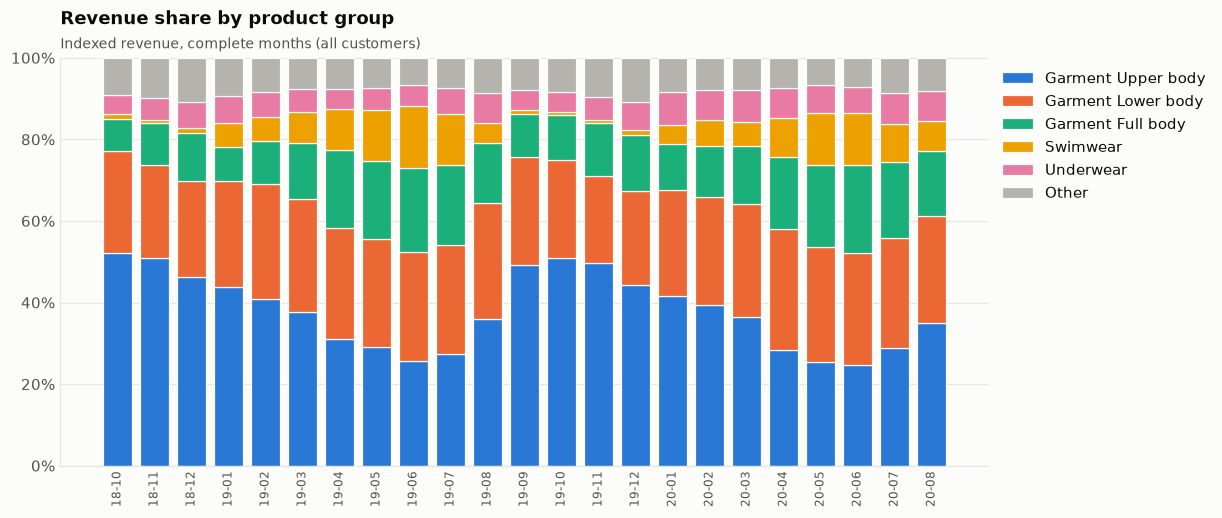

In [4]:
top5 = cat.groupby("category")["revenue"].sum().nlargest(5).index.tolist()
c2 = cat[cat.month.isin(full["month"])].copy()
c2["group"] = np.where(c2.category.isin(top5), c2.category, "Other")
share = c2.pivot_table(
    index="month", columns="group", values="revenue_share", aggfunc="sum"
).fillna(0)
share = share[top5 + ["Other"]]
fig, ax = viz.new_fig(11, 4.6)
viz.stacked_bars(ax, [m[2:] for m in share.index], {c: share[c] for c in share.columns})
viz.pct_axis(ax, "y")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_title("Revenue share by product group", pad=22)
viz.subtitle(ax, f"Indexed revenue, complete months ({SCOPE})")
viz.save_fig(fig, f"kpi_category_share_{MODE}", FIGURES)
plt.show()

Top 20 articles and top 20 styles (a style = `product_code`, all colour variants) by indexed revenue.

In [5]:
display(top_a)
display(top_s)

,rank,article_id,prod_name,product_type,colour,units,revenue,revenue_share,discounted_unit_share
0,1,706016001,Jade HW Skinny Denim TRS,Trousers,Black,50287,"1,631,732.102",0.002,0.255
1,2,706016002,Jade HW Skinny Denim TRS,Trousers,Light Blue,35043,"1,136,321.085",0.001,0.257
2,3,568601006,Mariette Blazer,Blazer,Black,19379,"939,268.593",0.001,0.298
3,4,448509014,Perrie Slim Mom Denim TRS,Trousers,Blue,19216,"781,478.390",0.001,0.212
4,5,706016003,Jade HW Skinny Denim TRS,Trousers,Dark Blue,21241,"692,195.915",0.001,0.234
5,6,399223001,Curvy Jeggings HW Ankle,Trousers,Black,22236,"686,484.780",0.001,0.378
6,7,720125001,SUPREME RW tights,Leggings/Tights,Black,21063,"683,606.542",0.001,0.272
7,8,562245046,Luna skinny RW,Trousers,Black,20719,"656,213.763",0.001,0.320
8,9,751471001,Pluto RW slacks (1),Trousers,Black,18263,"590,639.949",0.001,0.266
9,10,562245001,Luna skinny RW,Trousers,Black,20464,"535,719.898",0.001,0.616


,rank,product_code,prod_name,product_type,colour_variants,units,revenue,revenue_share,discounted_unit_share
0,1,706016,Jade HW Skinny Denim TRS,Trousers,27,183921,"5,876,158.119",0.007,0.280
1,2,562245,Luna skinny 5 pkt,Trousers,41,158557,"4,512,306.051",0.005,0.468
2,3,399201,Shaping Skinny H.W,Trousers,15,40116,"2,874,946.678",0.003,0.438
3,4,568601,Mariette Blazer,Blazer,23,54648,"2,598,120.576",0.003,0.334
4,5,695632,Gyda-,Blouse,40,75867,"2,344,477.034",0.003,0.364
5,6,399136,Shaping Skinny R.W.,Trousers,13,34988,"2,090,720.390",0.002,0.606
6,7,573085,Madison skinny HW (1),Trousers,25,68241,"2,073,390.898",0.002,0.340
7,8,554450,Julia RW Skinny Denim TRS,Trousers,23,67103,"2,070,574.542",0.002,0.327
8,9,751471,Pluto RW slacks (1),Trousers,22,64305,"2,065,257.271",0.002,0.282
9,10,399223,Jeggings H.W,Trousers,16,66253,"2,027,230.627",0.002,0.393


## 3. RFM segments

Share of customers vs share of revenue per segment: a small group of Champions and Loyal customers carries most of the revenue.

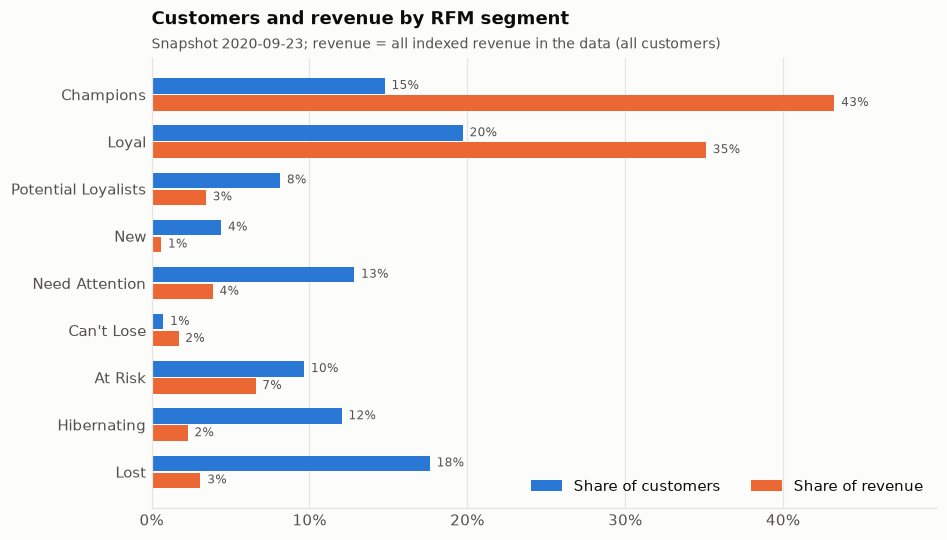

,segment,customers,customer_share,median_recency_days,avg_frequency,avg_monetary,monetary_share,revenue_at_stake,churned_share,channel2_share
0,Champions,201245,0.148,15.000,19.277,"1,901.742",0.433,"206,134,854.695",0.000,0.612
1,Loyal,268635,0.197,81.000,11.928,"1,156.575",0.351,"181,280,119.475",0.238,0.612
2,Potential Loyalists,110993,0.081,47.000,2.918,274.412,0.034,"24,137,807.458",0.000,0.681
3,New,60162,0.044,47.000,1.000,89.582,0.006,"5,389,454.627",0.000,0.711
4,Need Attention,174976,0.128,156.000,1.942,196.245,0.039,"29,783,407.220",0.774,0.826
5,Can't Lose,10196,0.007,292.000,15.177,"1,482.492",0.017,"12,775,417.203",1.000,0.603
6,At Risk,131756,0.097,359.000,4.671,442.268,0.066,"53,709,364.864",1.000,0.588
7,Hibernating,164109,0.120,341.000,1.312,123.294,0.023,"19,870,479.915",1.000,0.732
8,Lost,240209,0.176,620.000,1.196,114.181,0.031,"27,427,308.915",1.000,0.618


In [6]:
fig, ax = viz.new_fig(8.5, 4.8)
viz.hbar(
    ax,
    list(seg["segment"]),
    {"Share of customers": seg["customer_share"], "Share of revenue": seg["monetary_share"]},
)
viz.pct_axis(ax, "x")
ax.set_title("Customers and revenue by RFM segment", pad=22)
viz.subtitle(
    ax, f"Snapshot {info['snapshot_date']}; revenue = all indexed revenue in the data ({SCOPE})"
)
viz.save_fig(fig, f"rfm_segments_{MODE}", FIGURES)
plt.show()

display(
    seg[
        [
            "segment",
            "customers",
            "customer_share",
            "median_recency_days",
            "avg_frequency",
            "avg_monetary",
            "monetary_share",
            "revenue_at_stake",
            "churned_share",
            "channel2_share",
        ]
    ]
)

### Churn-window sensitivity

How many customers count as churned depends on the window. Segments themselves come from RFM scores and do not change with the window; their churned share does.

,segment,customers,churned_share_90d,churned_share_120d,churned_share_180d
0,Champions,201245,0.000,0.000,0.000
1,Loyal,268635,0.411,0.238,0.092
2,Potential Loyalists,110993,0.067,0.000,0.000
3,New,60162,0.072,0.000,0.000
4,Need Attention,174976,1.000,0.774,0.289
5,Can't Lose,10196,1.000,1.000,1.000
6,At Risk,131756,1.000,1.000,1.000
7,Hibernating,164109,1.000,1.000,1.000
8,Lost,240209,1.000,1.000,1.000
9,All customers,1362281,0.619,0.547,0.456


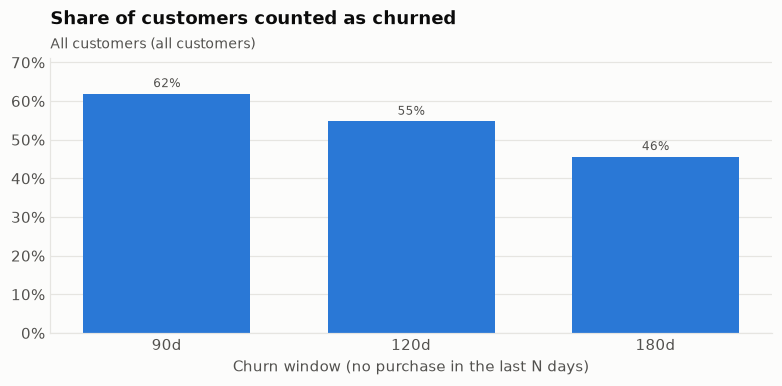

In [7]:
wcols = [c for c in sens.columns if c.startswith("churned_share_")]
display(sens[["segment", "customers", *wcols]])
tot = sens[sens.segment == "All customers"].iloc[0]
fig, ax = viz.new_fig(7, 3.4)
viz.vbar(
    ax,
    [c.removeprefix("churned_share_") for c in wcols],
    {"Churned share": [tot[c] for c in wcols]},
)
viz.pct_axis(ax, "y")
ax.set_xlabel("Churn window (no purchase in the last N days)")
ax.set_title("Share of customers counted as churned", pad=22)
viz.subtitle(ax, f"All customers ({SCOPE})")
viz.save_fig(fig, f"rfm_churn_sensitivity_{MODE}", FIGURES)
plt.show()

## 4. Cohort retention

Share of each monthly acquisition cohort that bought again *k* months later. Early cohorts include customers who were active before the data starts (Sep 2018), so they look stronger than true new-customer cohorts. The last month is partial.

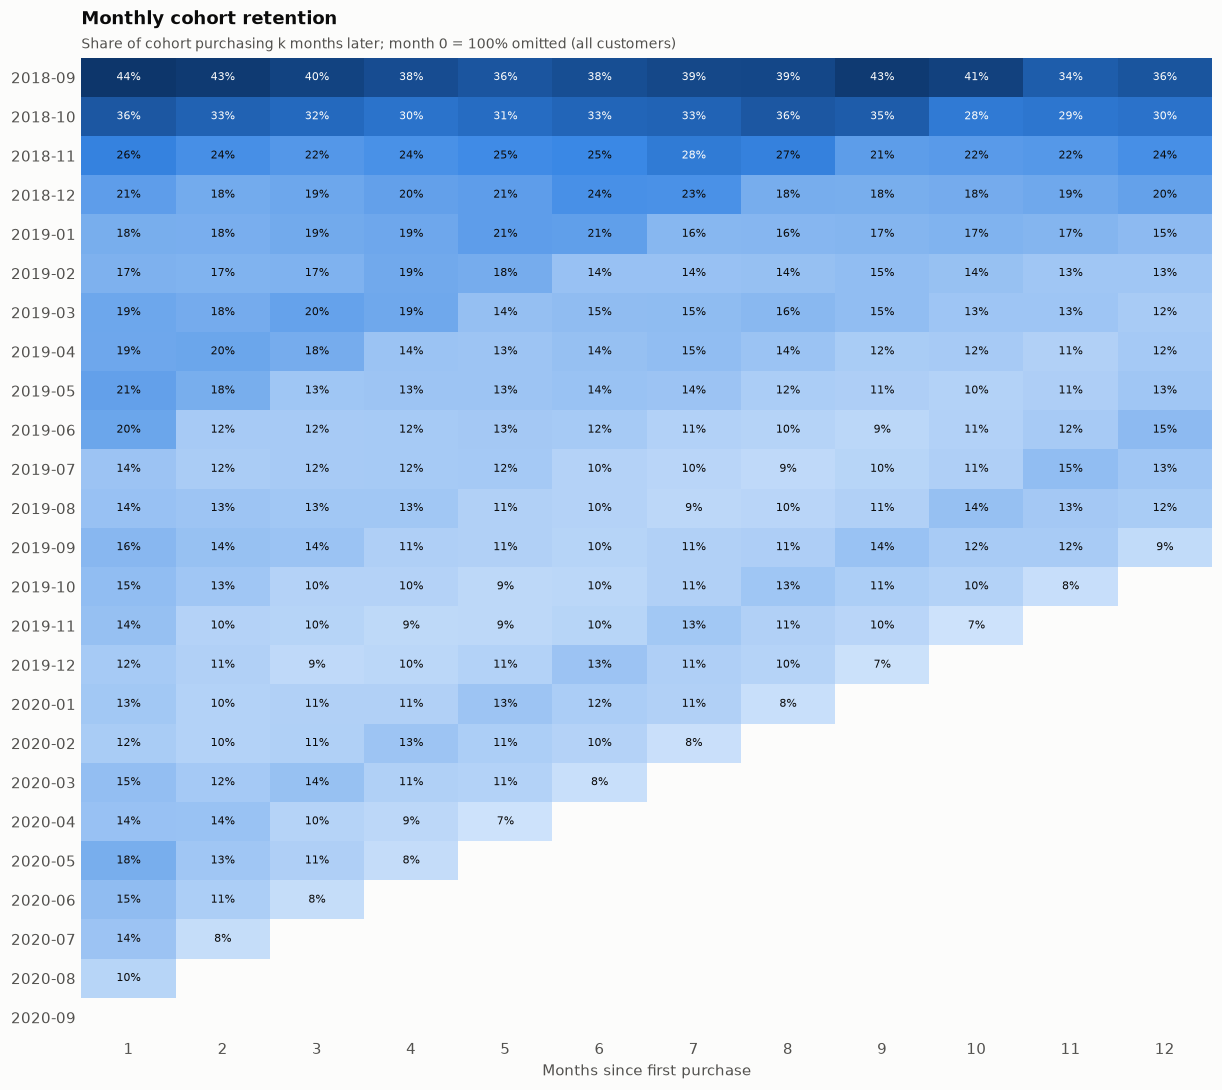

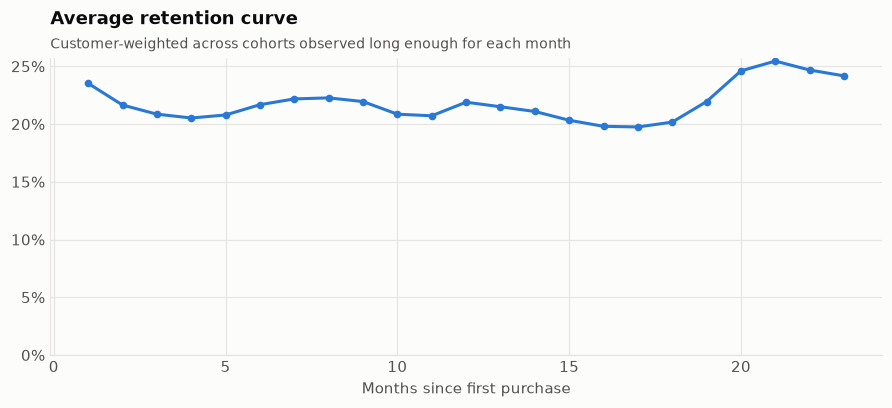

In [8]:
MAX_K = 12
wide = cohorts.retention_wide(ret, MAX_K).drop(columns=0)
fig, ax = viz.new_fig(11, 0.32 * len(wide) + 1.8)
viz.sequential_heatmap(
    ax, wide.to_numpy(dtype=float), list(wide.index), [str(c) for c in wide.columns]
)
ax.set_xlabel("Months since first purchase")
ax.set_title("Monthly cohort retention", pad=22)
viz.subtitle(ax, f"Share of cohort purchasing k months later; month 0 = 100% omitted ({SCOPE})")
viz.save_fig(fig, f"cohort_retention_{MODE}", FIGURES)
plt.show()

fig, ax = viz.new_fig(8, 3.6)
c1 = curve[curve.months_since.between(1, 23)]
ax.plot(c1["months_since"], c1["retention"], color=viz.SERIES[0], marker="o", markersize=4)
viz.pct_axis(ax, "y")
ax.set_ylim(bottom=0)
ax.set_xlabel("Months since first purchase")
ax.set_title("Average retention curve", pad=22)
viz.subtitle(ax, "Customer-weighted across cohorts observed long enough for each month")
viz.save_fig(fig, f"cohort_retention_curve_{MODE}", FIGURES)
plt.show()

## 5. Win-back playbook

For each churned or at-risk segment: size, revenue at stake, favourite categories, the discount band it over-indexes on, and an offer capped at the markdown ceiling. The rendered version is `reports/winback_playbook.md`.

Offer cap from the discount analysis: 15-25% -> max 20% off


,segment,customers,churned_share,revenue_at_stake,revenue_at_stake_per_customer,favourite_categories,discounted_unit_share,responds_to_band,offer_discount,offer_capped
0,Can't Lose,10196,1.000,"12,775,417.203","1,252.983","Garment Upper body (42%), Garment Lower body (...",0.403,55%+,0.200,True
1,At Risk,131756,1.000,"53,709,364.864",407.643,"Garment Upper body (41%), Garment Lower body (...",0.364,35-45%,0.200,True
2,Hibernating,164109,1.000,"19,870,479.915",121.081,"Garment Upper body (40%), Garment Lower body (...",0.452,5-15%,0.200,False
3,Lost,240209,1.000,"27,427,308.915",114.181,"Garment Upper body (43%), Garment Lower body (...",0.426,5-15%,0.150,False


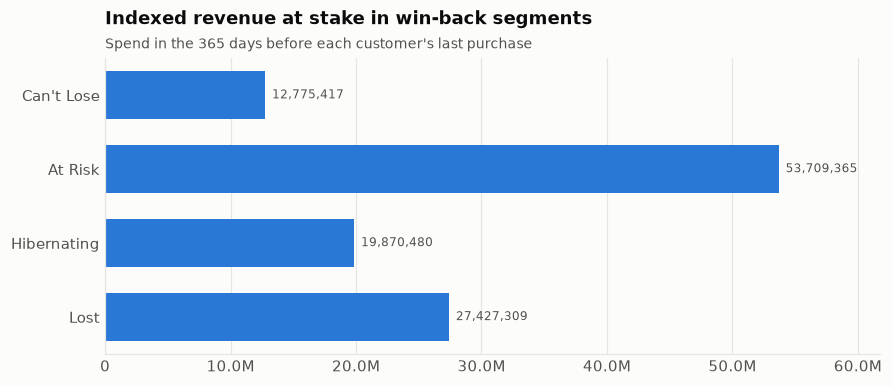

In [9]:
print(
    f"Offer cap from the discount analysis: {info['ceiling']['ceiling_band']} -> max {info['offer_cap']:.0%} off"
)
display(
    playbook[
        [
            "segment",
            "customers",
            "churned_share",
            "revenue_at_stake",
            "revenue_at_stake_per_customer",
            "favourite_categories",
            "discounted_unit_share",
            "responds_to_band",
            "offer_discount",
            "offer_capped",
        ]
    ]
)

fig, ax = viz.new_fig(8, 3.4)
viz.hbar(
    ax,
    list(playbook["segment"]),
    {"Revenue at stake": playbook["revenue_at_stake"]},
    label_fmt="{:,.0f}",
)
viz.thousands_axis(ax, "x")
ax.set_title("Indexed revenue at stake in win-back segments", pad=22)
viz.subtitle(ax, "Spend in the 365 days before each customer's last purchase")
viz.save_fig(fig, f"winback_revenue_at_stake_{MODE}", FIGURES)
plt.show()

## 6. Key facts

Computed from the tables above.

In [10]:
champ = seg[seg.segment.isin(["Champions", "Loyal"])]
best = full.loc[full["revenue"].idxmax()]
facts = pd.Series(
    {
        "Customers scored": f"{info['customers']:,}",
        "Champions + Loyal: share of customers / revenue": f"{champ.customer_share.sum():.0%} / {champ.monetary_share.sum():.0%}",
        "Win-back segments: customers": f"{int(playbook.customers.sum()):,} ({playbook.customer_share.sum():.0%})",
        "Win-back segments: indexed revenue at stake": f"{playbook.revenue_at_stake.sum():,.0f}",
        f"Churned at {W} days (all customers)": f"{sens.loc[sens.segment == 'All customers', f'churned_share_{W}d'].item():.0%}",
        "Month-1 retention (average)": f"{curve.loc[curve.months_since == 1, 'retention'].item():.0%}",
        "Highest-revenue complete month": best["month"],
        "Share of revenue sold at a discount (whole period)": f"{info['totals']['discounted_revenue_share']:.0%}",
        "Average order value (indexed)": f"{info['totals']['aov']:,.1f}",
    },
    name="value",
)
facts.to_frame()

,value
Customers scored,"1,362,281"
Champions + Loyal: share of customers / revenue,34% / 78%
Win-back segments: customers,"546,270 (40%)"
Win-back segments: indexed revenue at stake,"113,782,571"
Churned at 120 days (all customers),55%
Month-1 retention (average),24%
Highest-revenue complete month,2019-06
Share of revenue sold at a discount (whole period),32%
Average order value (indexed),96.4
